# 03 — Model evaluation & business threshold analysis

> **Prerequisite:** run `python main.py` from the project root first — this notebook reads the model artifacts, figures and SQL tables that the pipeline produces.

**Why not just accuracy?** Only 26.5% of customers churn, so "predict nobody churns" scores ~73.5% accuracy while catching zero churners. We evaluate with precision, recall, F1, ROC-AUC and PR-AUC, then choose an operating threshold with an explicit cost trade-off.

In [3]:
import sys
from pathlib import Path

# Make the src package importable when running from the notebooks/ folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 40)
FIG = PROJECT_ROOT / "reports" / "figures"

## Model comparison (held-out test set, threshold 0.50)

Two models trained on identical pipelines (median imputation + standard scaling for numeric, one-hot encoding for categoricals):
- **Logistic Regression** — interpretable baseline
- **HistGradientBoostingClassifier** — scikit-learn's gradient-boosted trees (same family as XGBoost, no extra dependency)

In [6]:
comparison = pd.read_csv(PROJECT_ROOT / "reports" / "model_comparison.csv")
comparison

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
0,logistic_regression,0.7935,0.6370,0.5160,0.5702,0.8419,0.6358,0.5
1,hist_gradient_boosting,0.7906,0.6295,0.5134,0.5655,0.8337,0.6364,0.5


In [7]:
import json
metadata = json.loads((PROJECT_ROOT / "models" / "model_metadata.json").read_text())
print(f"Selected model : {metadata['model_name']}")
print(f"Run id         : {metadata['run_id']}")
print(f"Operating threshold (F1-optimal, chosen on training folds): {metadata['threshold']}")
print(f"Cost-optimal threshold under the $5/$200 example          : {metadata['cost_optimal_threshold']}")
print("Test metrics at the operating threshold:")
metadata["test_metrics"]

Selected model : logistic_regression
Run id         : 24a699e1
Operating threshold (F1-optimal, chosen on training folds): 0.35
Cost-optimal threshold under the $5/$200 example          : 0.05
Test metrics at the operating threshold:


{'accuracy': 0.7736,
 'precision': 0.5579,
 'recall': 0.7086,
 'f1': 0.6243,
 'roc_auc': 0.8419,
 'pr_auc': 0.6358,
 'threshold': 0.35}

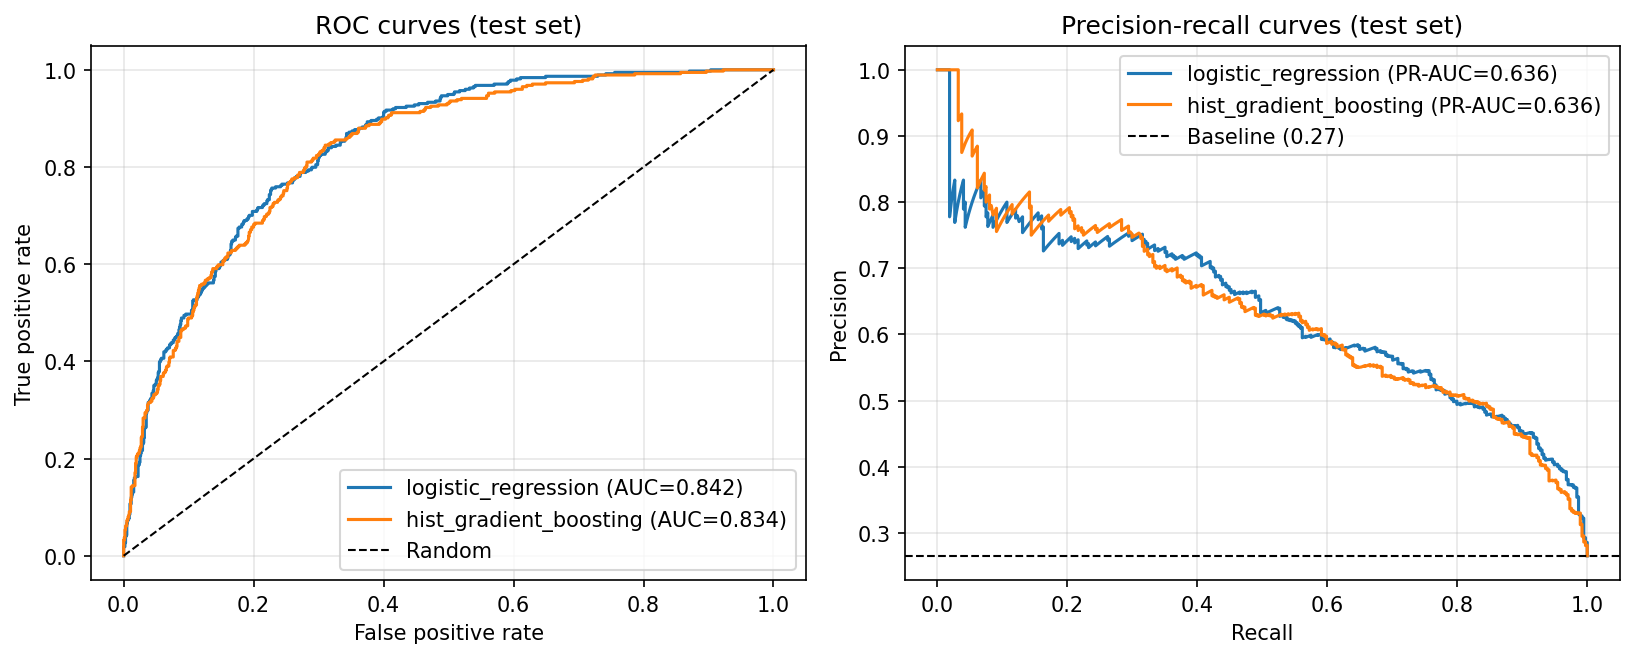

In [8]:
display(Image(filename=str(FIG / "10_roc_pr_curves.png"), width=850))

## Threshold analysis — 0.50 is not sacred

A classification threshold is a *business decision*, not a statistical default. The table below (test set, final model) shows how precision, recall and the error counts move as the threshold changes.

In [9]:
from src.evaluate import threshold_table

preds = pd.read_csv(PROJECT_ROOT / "reports" / "test_set_predictions.csv")
proba = preds[f"proba_{metadata['model_name']}"].values
y_true = preds["y_true"].values

tt = threshold_table(y_true, proba)
tt.round(3)

,threshold,precision,recall,f1,flagged,true_positives,false_positives,false_negatives,true_negatives,estimated_cost
0,0.05,0.356,0.984,0.523,1033,368,665,6,370,6365.0
1,0.10,0.408,0.947,0.570,868,354,514,20,521,8340.0
2,0.15,0.442,0.922,0.598,780,345,435,29,600,9700.0
3,0.20,0.477,0.853,0.612,669,319,350,55,685,14345.0
4,0.25,0.495,0.805,0.613,608,301,307,73,728,17640.0
5,0.30,0.530,0.765,0.626,540,286,254,88,781,20300.0
6,0.35,0.558,0.709,0.624,475,265,210,109,825,24175.0
7,0.40,0.577,0.663,0.617,430,248,182,126,853,27350.0
8,0.45,0.599,0.583,0.591,364,218,146,156,889,33020.0
9,0.50,0.637,0.516,0.570,303,193,110,181,925,37715.0


### A simple business-cost example (hypothetical numbers)

Assume:
- contacting a flagged customer costs **$5** (call + small offer),
- a churner we *miss* walks away with **$200** of future value,
- (simplification) a contacted churner is retained.

Estimated campaign cost = `$5 x customers flagged + $200 x churners missed`.

Because a missed churner costs **40x** a contact, the optimum is a **low threshold**: casting a wide net is cheap insurance. If the intervention were more expensive (say a $25 or $50 retention discount), the optimum shifts right and precision starts to matter — the sensitivity chart below shows exactly that.

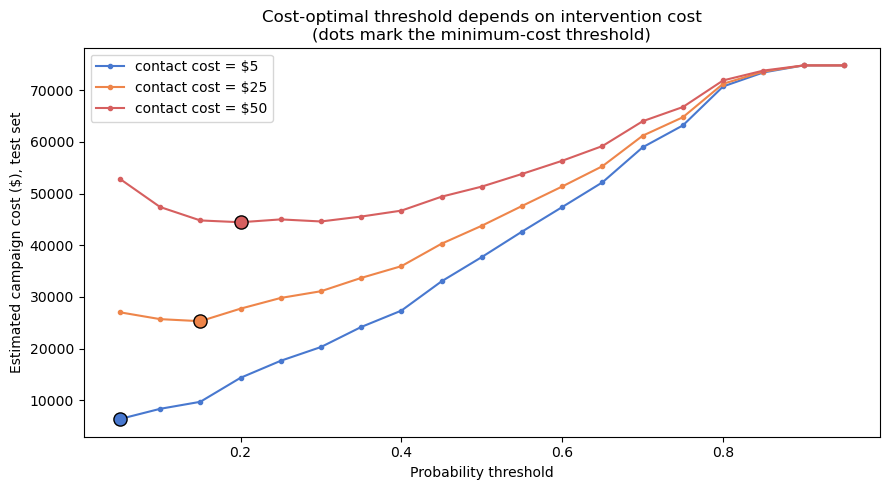

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
for cc, color in [(5, "#4878CF"), (25, "#EE854A"), (50, "#D65F5F")]:
    t = threshold_table(y_true, proba, contact_cost=cc)
    ax.plot(t["threshold"], t["estimated_cost"], marker="o", ms=3,
            color=color, label=f"contact cost = ${cc}")
    best = t.loc[t["estimated_cost"].idxmin()]
    ax.scatter(best["threshold"], best["estimated_cost"], s=90, color=color,
               zorder=5, edgecolor="black")
ax.set(title="Cost-optimal threshold depends on intervention cost\n(dots mark the minimum-cost threshold)",
       xlabel="Probability threshold", ylabel="Estimated campaign cost ($), test set")
ax.legend()
plt.tight_layout()
plt.show()

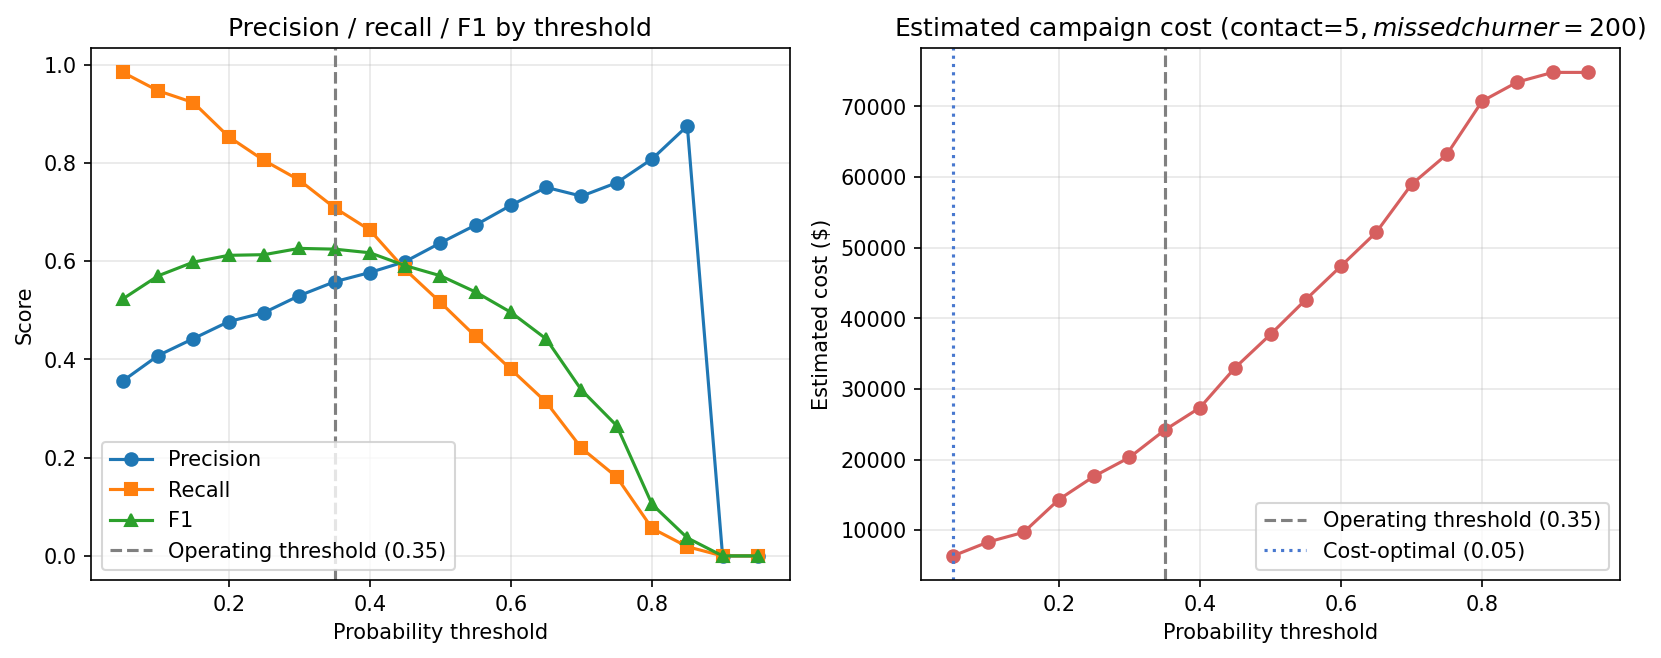

In [11]:
display(Image(filename=str(FIG / "12_threshold_analysis.png"), width=850))

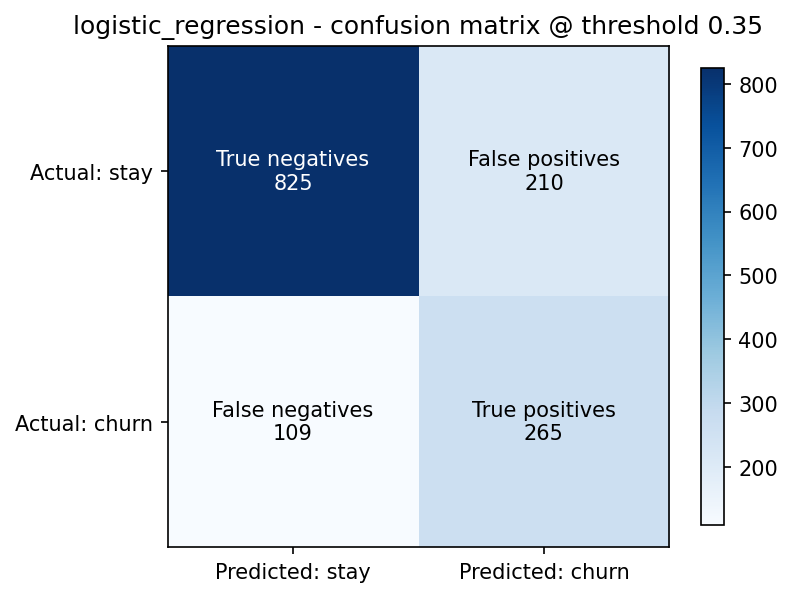

In [12]:
display(Image(filename=str(FIG / "11_confusion_matrix_final.png"), width=550))

## Explainability

### What the logistic regression says (global)

Coefficients are in log-odds on standardized features: red bars push customers toward churn, blue bars pull them away.

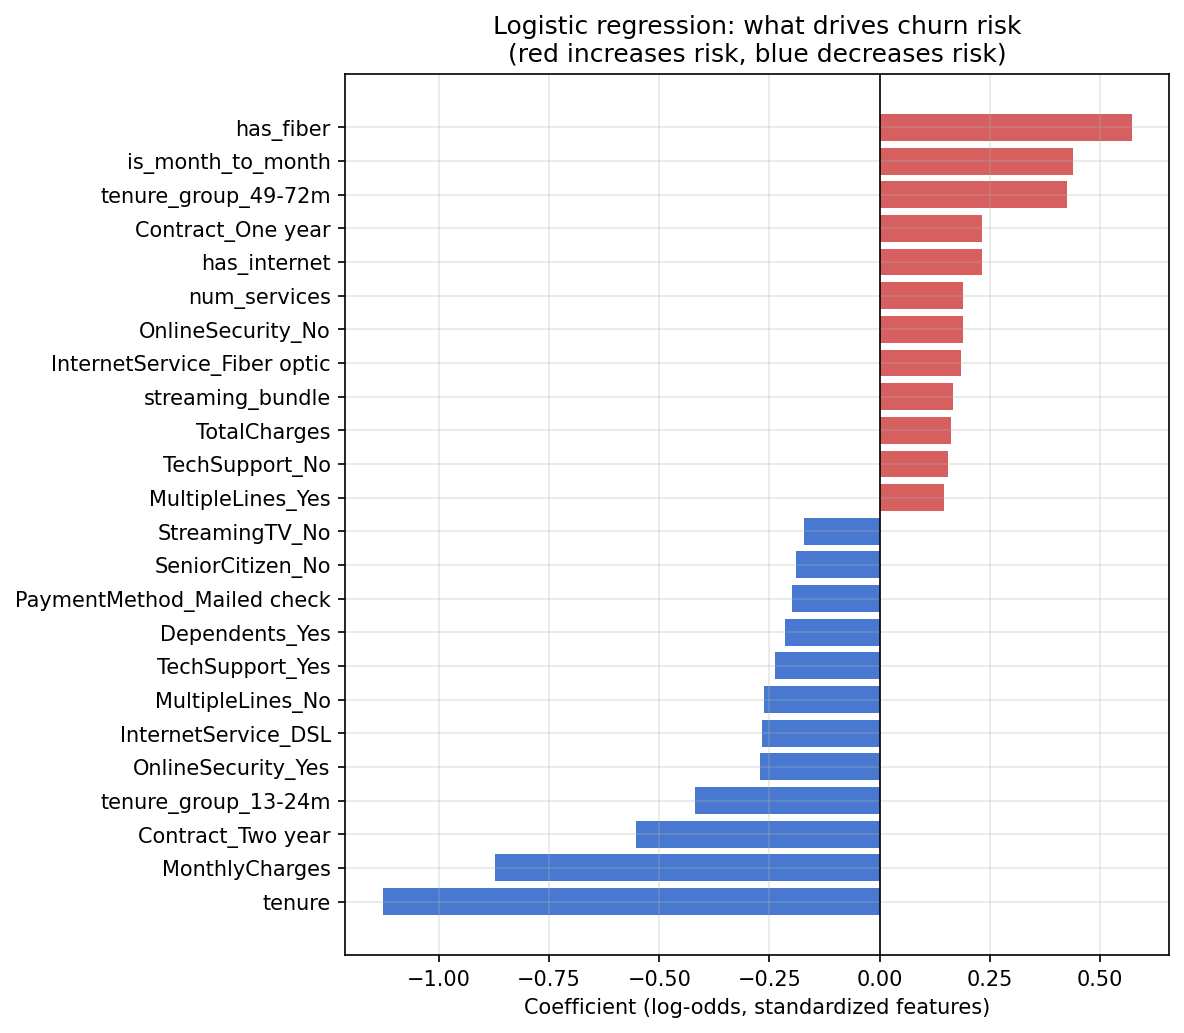

In [13]:
display(Image(filename=str(FIG / "13_logreg_coefficients.png"), width=750))

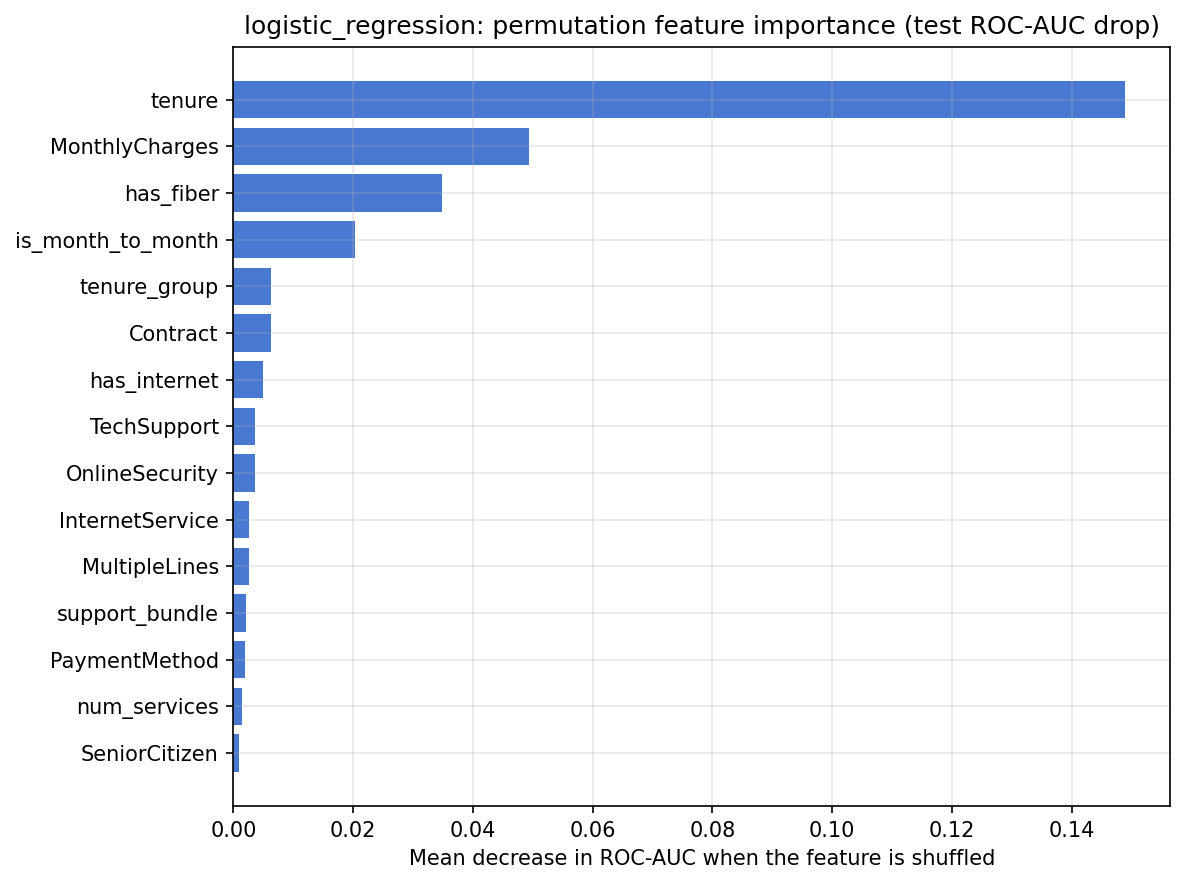

In [14]:
display(Image(filename=str(FIG / "14_final_model_feature_importance.png"), width=750))

### Why is *this* customer high-risk? (individual)

For each customer, the logistic regression's contribution of every feature (coefficient x standardized value) is computed; the top positive contributions are that customer's personal risk drivers. The pipeline saves the 20 riskiest test-set customers with their drivers:

In [15]:
pd.read_csv(PROJECT_ROOT / "reports" / "high_risk_explanations.csv").head(10)

,customer_id,churn_probability,top_risk_drivers
0,5178-LMXOP,0.8962,tenure (+1.45); has_fiber (+0.64); is_month_to...
1,0295-PPHDO,0.8764,tenure (+1.45); has_fiber (+0.64); is_month_to...
2,1400-MMYXY,0.8738,tenure (+1.35); has_fiber (+0.64); is_month_to...
3,6861-XWTWQ,0.8726,tenure (+1.17); has_fiber (+0.64); is_month_to...
4,6023-YEBUP,0.8718,tenure (+1.35); has_fiber (+0.64); is_month_to...
5,8884-ADFVN,0.8668,tenure (+1.17); has_fiber (+0.64); is_month_to...
6,9057-SIHCH,0.8624,tenure (+1.35); has_fiber (+0.64); is_month_to...
7,8161-QYMTT,0.8566,tenure (+1.17); has_fiber (+0.64); is_month_to...
8,2545-EBUPK,0.8393,tenure (+1.40); has_fiber (+0.64); is_month_to...
9,3722-WPXTK,0.8377,tenure (+1.45); has_fiber (+0.64); is_month_to...


## Predictions in SQL

`python main.py score` writes every customer's churn probability back to the `churn_predictions` table, and reporting views aggregate them for stakeholders:

In [16]:
from src.database import get_engine, read_query

engine = get_engine()
read_query("SELECT * FROM v_risk_by_contract", engine)

,Contract,customers,avg_churn_probability,predicted_churn_rate,actual_churn_rate
0,Month-to-month,3875,0.428,0.587,0.427
1,One year,1473,0.112,0.027,0.113
2,Two year,1695,0.029,0.000,0.028


In [17]:
read_query("SELECT * FROM v_highest_risk_customers LIMIT 10", engine)

,customer_id,churn_probability,Contract,tenure,MonthlyCharges,InternetService,PaymentMethod
0,5178-LMXOP,0.896,Month-to-month,1,95.10,Fiber optic,Electronic check
1,9497-QCMMS,0.896,Month-to-month,1,93.55,Fiber optic,Electronic check
2,9300-AGZNL,0.895,Month-to-month,1,94.00,Fiber optic,Electronic check
3,4424-TKOPW,0.894,Month-to-month,2,93.85,Fiber optic,Electronic check
4,5150-ITWWB,0.894,Month-to-month,3,94.85,Fiber optic,Electronic check
5,7216-EWTRS,0.893,Month-to-month,1,100.80,Fiber optic,Electronic check
6,2720-WGKHP,0.890,Month-to-month,2,94.00,Fiber optic,Electronic check
7,5567-WSELE,0.889,Month-to-month,3,94.60,Fiber optic,Electronic check
8,1374-DMZUI,0.887,Month-to-month,4,94.30,Fiber optic,Electronic check
9,7024-OHCCK,0.886,Month-to-month,2,93.85,Fiber optic,Electronic check


## Business recommendations

1. **Target month-to-month, first-year customers** — the model's top risk drivers align with the EDA: offer contract-upgrade incentives early.
2. **Investigate the fiber-optic experience** — premium price with the highest churn suggests a value-perception problem.
3. **Promote automatic payments** — auto-pay customers churn far less; a small discount for enrolling may pay for itself.
4. **Set the campaign threshold from economics, not defaults** — with cheap contacts, flag aggressively (high recall); with costly offers, raise the threshold (high precision).

**Limitations:** single snapshot (no time dimension), hypothetical cost numbers, retention success assumed rather than measured, and the dataset is a stylized IBM sample.